In [1]:

import geopandas as gpd
import os
import re
import requests
import boto3
from rasterio.session import AWSSession
import numpy as np
import rasterio
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
import leafmap.maplibregl as leafmap

In [2]:
# 1. Ruta a tu archivo vectorial
aoi_path = "C:/Users/CAMILO/Desktop/Vectorial/Monserrate.shp"  # Cambia esto por tu archivo (.geojson, .shp, .gpkg)

# 2. Cargar el archivo vectorial usando GeoPandas  
gdf_aoi = gpd.read_file(aoi_path)

# 3. Garantizar que el CRS esté en WGS84 (EPSG:4326) para la API OData de CDSE
if gdf_aoi.crs != "EPSG:4326":
    gdf_aoi = gdf_aoi.to_crs(epsg=4326)

# 4. Extraer la geometría unificada y el Bounding Box (bbox)
# Si el archivo tiene múltiples polígonos, .union_all() los combina en uno solo
aoi_geometry = gdf_aoi.geometry.union_all()

# Obtener las coordenadas extremas [minx, miny, maxx, maxy]
minx, miny, maxx, maxy = aoi_geometry.bounds

print(" Sistema de Referencia Espacial (CRS):", gdf_aoi.crs)
print(" Extensión Geográfica (Bounding Box):", [minx, miny, maxx, maxy])
print(" Geometría WKT (Well-Known Text):", aoi_geometry.wkt[:100], "...")

 Sistema de Referencia Espacial (CRS): EPSG:4326
 Extensión Geográfica (Bounding Box): [-76.00515626999999, 2.441915601000062, -75.96800748199996, 2.5040494410000633]
 Geometría WKT (Well-Known Text): POLYGON ((-75.97458799699996 2.5022224710000387, -75.97445620199994 2.5021874660000663, -75.97432574 ...


In [3]:
os.environ["AWS_ACCESS_KEY_ID"] ="MMGLFL1X5TDP7637YWN8"
os.environ["AWS_SECRET_ACCESS_KEY"] = "Q1s94tsudm2Zh6OwZJw4xaQYt4nmqVYoBKPnEXFV"
os.environ["AWS_S3_ENDPOINT"] = "eodata.dataspace.copernicus.eu"
os.environ["AWS_VIRTUAL_HOSTING"] = "FALSE"
os.environ["GDAL_HTTP_UNSAFESSL"] = "YES"
os.environ["AWS_HTTPS"] = "YES"
os.environ["GDAL_HTTP_TCP_KEEPALIVE"] = "YES"

In [4]:
# Define a  function to inspect directories and raster datasets in Copernicus S3
def list_s3_resources(prefix_path=""):
    """
    Lists sub-directories and raster files (.tif, .tiff, .jp2) 
    within the Copernicus 'eodata' S3 bucket for a given prefix path.
    """
    s3_client = boto3.client(
        "s3",
        aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
        aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"],
        endpoint_url=f"https://{os.environ['AWS_S3_ENDPOINT']}"
    )
    
    response = s3_client.list_objects_v2(
        Bucket="eodata",
        Prefix=prefix_path,
        Delimiter="/"
    )
    
    print(f"--- Contents in s3://eodata/{prefix_path} ---")
    # Print available subfolders and satellite collections
    folders = response.get("CommonPrefixes", [])
    for folder in folders:
        print(" 📁", folder.get("Prefix"))
        
    # Print raster data files if situated at the terminal folder level
    files = response.get("Contents", [])
    for file in files:
        key = file.get("Key")
        if key.endswith((".tif", ".tiff", ".jp2")):
            print(" 📄 /vsis3/eodata/" + key)

# List all primary satellite collections available at root level
list_s3_resources("")

--- Contents in s3://eodata/ ---
 📁 C3S/
 📁 CAMS/
 📁 CCM/
 📁 CEMS/
 📁 CLMS/
 📁 CLMS_archive/
 📁 Envisat-ASAR/
 📁 Envisat/
 📁 Global-Mosaics/
 📁 Jason-3/
 📁 Landsat-5/
 📁 Landsat-7/
 📁 SMOS/
 📁 SRTM/
 📁 Sentinel-1-RTC/
 📁 Sentinel-1/
 📁 Sentinel-2/
 📁 Sentinel-3/
 📁 Sentinel-5P/
 📁 Sentinel-6/
 📁 auxdata/
 📁 geoAI-embeddings/
 📁 geoAI-training/


In [5]:
# Coordenadas geográficas del área de estudio (Bounding Box en EPSG:4326)
MIN_LON = -76.00515627
MIN_LAT = 2.441915601
MAX_LON = -75.96800748
MAX_LAT = 2.504049441

print(f"✅ Coordenadas definidas:")
print(f"   Lon: [{MIN_LON}, {MAX_LON}]")
print(f"   Lat: [{MIN_LAT}, {MAX_LAT}]")

✅ Coordenadas definidas:
   Lon: [-76.00515627, -75.96800748]
   Lat: [2.441915601, 2.504049441]


In [9]:
import re
import requests

# Coordenadas centrales derivadas de tu Bounding Box [-76.00515, 2.44191, -75.96800, 2.50404]
LATITUDE = 2.47298
LONGITUDE = -75.98658

def search_Monserrate_odata(lat, lon, start_date, end_date):
    """Queries the Copernicus OData endpoint for Sentinel-2 Level-2A products
    intersecting a spatial bounding box around the target location.
    Returns a structured list containing metadata for each matching satellite scene.
    """
    url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

    # Bounding box buffer (~10 km x 10 km)
    min_lon, max_lon = lon - 0.05, lon + 0.05
    min_lat, max_lat = lat - 0.05, lat + 0.05
    
    # Well-Known Text (WKT) POLYGON string sin espacios entre POLYGON y ((
    poly = f"POLYGON(({min_lon} {min_lat}, {max_lon} {min_lat}, {max_lon} {max_lat}, {min_lon} {max_lat}, {min_lon} {min_lat}))"

    # OData Query String corregida para la API OData v1 de CDSE
    filter_query = (
        f"Collection/Name eq 'SENTINEL-2' and "
        f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'productType' and att/Value eq 'S2MSI2A') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{poly}') and "
        f"ContentDate/Start ge {start_date}T00:00:00.000Z and "
        f"ContentDate/Start le {end_date}T23:59:59.999Z"
    )
    
    params = {
        "$filter": filter_query,
        "$orderby": "ContentDate/Start desc",
        "$top": 50,
    }

    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()
    
    items = data.get("value", [])
    results = []
    
    print(f" Found {len(items)} matching Level-2A satellite scenes for range [{start_date} - {end_date}].\n" + "=" * 70)

    for idx, item in enumerate(items):
        s3_path = item.get("S3Path", "")
        date = item.get("ContentDate", {}).get("Start", "").split("T")[0]

        match = re.search(r"_(T\d{2}[A-Z]{3})_", s3_path)
        tile_id = match.group(1) if match else "N/A"

        results.append(
            {"index": idx, "date": date, "tile": tile_id, "s3_path": s3_path}
        )

        print(f"[{idx}] 📅 Date: {date} | 🧩 Detected tile: {tile_id}")
        print(f"    📦 S3 path: {s3_path}\n")

    return results

# ==========================================
# ESCENARIO 1: Marzo 2023
# ==========================================
print("🔴 EJECUTANDO BUSQUEDA - ESCENARIO 1 (Marzo 2023)")
escenario_1 = search_Monserrate_odata(
    LATITUDE, LONGITUDE, "2023-03-01", "2023-03-31"
)

# ==========================================
# ESCENARIO 2: Marzo 2024
# ==========================================
print("\n🔵 EJECUTANDO BUSQUEDA - ESCENARIO 2 (Marzo 2024)")
escenario_2 = search_Monserrate_odata(
    LATITUDE, LONGITUDE, "2024-03-01", "2024-03-31"
)

🔴 EJECUTANDO BUSQUEDA - ESCENARIO 1 (Marzo 2023)
 Found 6 matching Level-2A satellite scenes for range [2023-03-01 - 2023-03-31].
[0] 📅 Date: 2023-03-29 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/29/S2B_MSIL2A_20230329T152639_N0510_R025_T18NUH_20240824T030224.SAFE

[1] 📅 Date: 2023-03-24 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/24/S2A_MSIL2A_20230324T152641_N0510_R025_T18NUH_20240824T123203.SAFE

[2] 📅 Date: 2023-03-19 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/19/S2B_MSIL2A_20230319T152639_N0510_R025_T18NUH_20240825T073251.SAFE

[3] 📅 Date: 2023-03-14 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/14/S2A_MSIL2A_20230314T152641_N0510_R025_T18NUH_20240821T042223.SAFE

[4] 📅 Date: 2023-03-09 | 🧩 Detected tile: T18NUH
    📦 S3 path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/03/09/S2B_MSIL2A_20230309T152649_N0510_R025_T18NUH_20240823T123510.S

In [10]:
import os
import boto3
import rasterio
import numpy as np
import geopandas as gpd
from rasterio.session import AWSSession
from rasterio.mask import mask
from shapely.wkt import loads
import matplotlib.pyplot as plt

# 1. Rutas S3 de tus 2 escenas seleccionadas (Reemplaza con tus rutas exactas)
S3_PATH_ESCENARIO_1 = "eodata/Sentinel-2/MSI/L2A/2023/03/15/S2B_MSIL2A_20230315T...SAFE"
S3_PATH_ESCENARIO_2 = "eodata/Sentinel-2/MSI/L2A/2024/03/15/S2A_MSIL2A_20240315T...SAFE"

# 2. Configurar cliente Boto3 y AWSSession para Rasterio Directo
session = boto3.Session(
    aws_access_key_id=os.environ["AWS_ACCESS_KEY_ID"],
    aws_secret_access_key=os.environ["AWS_SECRET_ACCESS_KEY"]
)
endpoint_url = f"https://{os.environ['AWS_S3_ENDPOINT']}"

# 3. Geometría de tu SHP en EPSG:4326
wkt_geometry = "POLYGON ((-75.97458799699996 2.5022224710000387, -75.97445620199994 2.5021874660000663, -75.97432574 2.502, -76.00515627 2.44191560, -75.96800748 2.44191560, -75.97458799699996 2.5022224710000387))"
geom_shape = loads(wkt_geometry)
gdf = gpd.GeoDataFrame(index=[0], crs="EPSG:4326", geometry=[geom_shape])

In [11]:
def process_ndvi_from_s3(s3_safe_path, gdf_aoi):
    """Accede a las bandas B04 y B08 en S3, recorta con la geometría dada y calcula NDVI."""
    
    # Construir ruta a la subcarpeta GRANULE / R10m
    # Nota: Las imágenes de 10m (B04 y B08) están en GRANULE/.../IMG_DATA/R10m/
    s3_base = f"s3://{s3_safe_path.strip('/')}/GRANULE"
    
    # Usar boto3 para localizar la carpeta exacta del gránulo
    s3_client = session.client("s3", endpoint_url=endpoint_url)
    bucket = "eodata"
    prefix = s3_safe_path.replace("eodata/", "").strip("/") + "/GRANULE/"
    
    resp = s3_client.list_objects_v2(Bucket=bucket, Prefix=prefix, Delimiter="/")
    granule_folder = resp.get("CommonPrefixes", [{}])[0].get("Prefix", "")
    
    # Rutas relativas a las bandas B04 (Red) y B08 (NIR)
    # Se busca el patrón _B04_10m.jp2 y _B08_10m.jp2
    r10m_prefix = granule_folder + "IMG_DATA/R10m/"
    resp_bands = s3_client.list_objects_v2(Bucket=bucket, Prefix=r10m_prefix)
    
    b04_key, b08_key = None, None
    for obj in resp_bands.get("Contents", []):
        key = obj["Key"]
        if key.endswith("B04_10m.jp2"):
            b04_key = key
        elif key.endswith("B08_10m.jp2"):
            b08_key = key
            
    aws_env = rasterio.env.Env(
        AWSSession(session, endpoint_url=endpoint_url),
        GDAL_DISABLE_READDIR_BEFORE_SIDECAR=True,
        AWS_S3_ENDPOINT=os.environ['AWS_S3_ENDPOINT']
    )
    
    with aws_env:
        # Abrir B04 y B08
        with rasterio.open(f"s3://{bucket}/{b04_key}") as src_red:
            # Reproyectar GeoDataFrame al CRS UTM de la imagen Sentinel-2
            gdf_utm = gdf_aoi.to_crs(src_red.crs)
            shapes = [gdf_utm.geometry.iloc[0]]
            
            # Recortar B04
            red_crop, _ = mask(src_red, shapes, crop=True)
            red = red_crop[0].astype(float)
            
        with rasterio.open(f"s3://{bucket}/{b08_key}") as src_nir:
            # Recortar B08
            nir_crop, _ = mask(src_nir, shapes, crop=True)
            nir = nir_crop[0].astype(float)
            
    # Calcular NDVI (evitando división por cero)
    denominator = nir + red
    ndvi = np.where(denominator == 0, np.nan, (nir - red) / denominator)
    ndvi = np.where((red == 0) & (nir == 0), np.nan, ndvi)
    
    return ndvi

In [22]:
import numpy as np
import rioxarray as rxr

# 1. Cargar las capas GeoTIFF guardadas
ds_e1 = rxr.open_rasterio("ndvi_estado1_rioxarray.tif").squeeze()
ds_e2 = rxr.open_rasterio("ndvi_estado2_rioxarray.tif").squeeze()

# 2. Calcular la capa de diferencia
ds_diff = ds_e2 - ds_e1
ds_diff.rio.to_raster("ndvi_diferencia_rioxarray.tif", dtype="float32")

# 3. Filtrar valores nulos para extraer métricas biológicas puras
v1 = ds_e1.values[~np.isnan(ds_e1.values)]
v2 = ds_e2.values[~np.isnan(ds_e2.values)]
vd = ds_diff.values[~np.isnan(ds_diff.values)]

print("📊 ESTADÍSTICAS DEL NDVI (ÁREA DE ESTUDIO - CAUCA):")
print(f"• 2023 (E1) -> Mín: {v1.min():.3f} | Máx: {v1.max():.3f} | Media: {v1.mean():.3f} | Desv: {v1.std():.3f}")
print(f"• 2024 (E2) -> Mín: {v2.min():.3f} | Máx: {v2.max():.3f} | Media: {v2.mean():.3f} | Desv: {v2.std():.3f}")
print(f"• Cambio Δ   -> Mín: {vd.min():.3f} | Máx: {vd.max():.3f} | Media: {vd.mean():.3f} | Desv: {vd.std():.3f}")

📊 ESTADÍSTICAS DEL NDVI (ÁREA DE ESTUDIO - CAUCA):
• 2023 (E1) -> Mín: 1.000 | Máx: 1.000 | Media: 1.000 | Desv: 0.000
• 2024 (E2) -> Mín: 0.035 | Máx: 0.172 | Media: 0.080 | Desv: 0.024
• Cambio Δ   -> Mín: -0.965 | Máx: -0.828 | Media: -0.920 | Desv: 0.024


In [35]:
import leafmap
import rioxarray as rxr
import numpy as np

# ==============================================================================
# 1. CARGAR Y REPROYECTAR RASTERS A EPSG:4326 (WGS84 GEOGRÁFICAS)
# ==============================================================================
# Reproyectar en memoria para asegurar compatibilidad total con el visor Leaflet
tif_e1 = rxr.open_rasterio("ndvi_estado1_rioxarray.tif", masked=True).squeeze()
tif_e2 = rxr.open_rasterio("ndvi_estado2_rioxarray.tif", masked=True).squeeze()

tif_e1_4326 = tif_e1.rio.reproject("EPSG:4326")
tif_e2_4326 = tif_e2.rio.reproject("EPSG:4326")

# Guardar versiones temporales en EPSG:4326
path_e1_web = "ndvi_e1_web.tif"
path_e2_web = "ndvi_e2_web.tif"

tif_e1_4326.rio.to_raster(path_e1_web, dtype="float32")
tif_e2_4326.rio.to_raster(path_e2_web, dtype="float32")

# ==============================================================================
# 2. DEFINIR CENTROIDE Y RANGO DINÁMICO
# ==============================================================================
if 'gdf' in locals():
    gdf_4326 = gdf.to_crs("EPSG:4326")
    center_lat = float(gdf_4326.geometry.centroid.y.iloc[0])
    center_lon = float(gdf_4326.geometry.centroid.x.iloc[0])
else:
    center_lat, center_lon = 2.472, -75.986

vals_validos = tif_e1_4326.values[~np.isnan(tif_e1_4326.values)]
vmin_val = float(np.percentile(vals_validos, 2)) if len(vals_validos) > 0 else 0.1
vmax_val = float(np.percentile(vals_validos, 98)) if len(vals_validos) > 0 else 0.8

viz_args = {
    "cmap": "YlGn",
    "vmin": vmin_val,
    "vmax": vmax_val,
    "nodata": np.nan
}

# ==============================================================================
# 3. RENDERIZAR SPLIT MAP CON BASEMAP EXPLÍCITO (HYBRID O OpenStreetMap)
# ==============================================================================
# Forzar el mapa base a hibrido de satélite con etiquetas
m_split = leafmap.Map(center=[center_lat, center_lon], zoom=14)
m_split.add_basemap("HYBRID")

m_split.split_map(
    left_layer=path_e1_web,
    right_layer=path_e2_web,
    left_label="NDVI 2023 (Estado 1)",
    right_label="NDVI 2024 (Estado 2)",
    left_args=viz_args,
    right_args=viz_args
)

m_split

Map(center=[2.4618132750790997, -75.98256251118238], controls=(ZoomControl(options=['position', 'zoom_in_text'…

In [38]:
# Imprimir el área aproximada en hectáreas y la envolvente (Bounding Box)
gdf_utm = gdf.to_crs(epsg=3116)  # MAGNA-SIRGAS Colombia / Origen Nacional
area_ha = gdf_utm.geometry.area.sum() / 10000

print(f"📐 Área exacta del Shapefile cargado: {area_ha:.2f} hectáreas")
print(f"🗺️ Bounding Box WGS84: {list(gdf.total_bounds)}")

📐 Área exacta del Shapefile cargado: 1365.19 hectáreas
🗺️ Bounding Box WGS84: [np.float64(-76.00515627), np.float64(2.4419156), np.float64(-75.96800748), np.float64(2.5022224710000387)]


In [37]:
import os
import requests
import rasterio
import rioxarray as rxr
import xarray as xr
import numpy as np
import leafmap

# 1. BÚSQUEDA DE ESCENAS LIMPIAS EN STAC
def get_stac_scene(start_date, end_date, gdf_aoi):
    stac_url = "https://stac.dataspace.copernicus.eu/v1/search"
    bbox = list(gdf_aoi.to_crs("EPSG:4326").total_bounds)
    
    payload = {
        "collections": ["sentinel-2-l2a"],
        "bbox": bbox,
        "datetime": f"{start_date}/{end_date}",
        "query": {"eo:cloud_cover": {"lt": 20}},
        "limit": 5
    }
    
    res = requests.post(stac_url, json=payload, timeout=30).json()
    features = res.get("features", [])
    
    if not features:
        payload["query"]["eo:cloud_cover"] = {"lt": 40}
        res = requests.post(stac_url, json=payload, timeout=30).json()
        features = res.get("features", [])

    for feat in features:
        assets = feat.get("assets", {})
        cloud = feat.get("properties", {}).get("eo:cloud_cover", "N/A")
        date = feat.get("properties", {}).get("datetime", "")[:10]
        
        b04 = assets.get("B04") or assets.get("red") or assets.get("B04_10m")
        b08 = assets.get("B08") or assets.get("nir") or assets.get("B08_10m")
        
        u04 = b04.get("href") if isinstance(b04, dict) else None
        u08 = b08.get("href") if isinstance(b08, dict) else None
        
        if u04 and u08:
            print(f"  • Escena seleccionada ({date}): {cloud}% nubes")
            return u04, u08
            
    raise ValueError("❌ No se encontraron escenas con baja nubosidad.")

print("🔍 Buscando escenas sobre el Cauca...")
print("► Estado 1 (2023):")
url_b04_e1, url_b08_e1 = get_stac_scene("2023-01-01T00:00:00Z", "2023-12-31T23:59:59Z", gdf)
print("► Estado 2 (2024):")
url_b04_e2, url_b08_e2 = get_stac_scene("2024-01-01T00:00:00Z", "2024-12-31T23:59:59Z", gdf)

# 2. CONVERSIÓN SEGURA A /vsis3/ O /vsicurl/
def format_gdal_path(url):
    if url.startswith("s3://"):
        return url.replace("s3://", "/vsis3/")
    elif "eodata/" in url:
        clean_path = url.split("eodata/")[1]
        return f"/vsis3/eodata/{clean_path}"
    return f"/vsicurl/{url}"

vsi_b04_e1 = format_gdal_path(url_b04_e1)
vsi_b08_e1 = format_gdal_path(url_b08_e1)
vsi_b04_e2 = format_gdal_path(url_b04_e2)
vsi_b08_e2 = format_gdal_path(url_b08_e2)

# 3. PROCESAMIENTO RIOXARRAY USANDO CREDENCIALES S3
print("\n⚡ Procesando bandas con S3 autenticado...")
gdal_env = {
    "GDAL_DISABLE_READDIR_BEFORE_SIDECAR": "YES",
    "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": "jp2,tif,tiff",
}

with rasterio.Env(**gdal_env):
    # --- Estado 1 (2023) ---
    r1 = rxr.open_rasterio(vsi_b04_e1, masked=True).squeeze()
    n1 = rxr.open_rasterio(vsi_b08_e1, masked=True).squeeze()
    g1 = gdf.to_crs(r1.rio.crs)
    r1_c = r1.rio.clip(g1.geometry, g1.crs, drop=True)
    n1_c = n1.rio.clip(g1.geometry, g1.crs, drop=True)
    
    d1 = n1_c + r1_c
    ndvi1 = xr.where(d1 == 0, np.nan, (n1_c - r1_c) / d1)
    ndvi1 = ndvi1.rio.write_crs(r1_c.rio.crs, inplace=True).rio.write_transform(r1_c.rio.transform(), inplace=True)
    ndvi1_4326 = ndvi1.rio.reproject("EPSG:4326")

    # --- Estado 2 (2024) ---
    r2 = rxr.open_rasterio(vsi_b04_e2, masked=True).squeeze()
    n2 = rxr.open_rasterio(vsi_b08_e2, masked=True).squeeze()
    g2 = gdf.to_crs(r2.rio.crs)
    r2_c = r2.rio.clip(g2.geometry, g2.crs, drop=True)
    n2_c = n2.rio.clip(g2.geometry, g2.crs, drop=True)
    
    d2 = n2_c + r2_c
    ndvi2 = xr.where(d2 == 0, np.nan, (n2_c - r2_c) / d2)
    ndvi2 = ndvi2.rio.write_crs(r2_c.rio.crs, inplace=True).rio.write_transform(r2_c.rio.transform(), inplace=True)
    ndvi2_4326 = ndvi2.rio.reproject("EPSG:4326")

# Guardar rasters corregidos
f1_clean = "ndvi_2023_limpio.tif"
f2_clean = "ndvi_2024_limpio.tif"
ndvi1_4326.rio.to_raster(f1_clean, dtype="float32")
ndvi2_4326.rio.to_raster(f2_clean, dtype="float32")

# 4. VERIFICAR ESTADÍSTICAS
v1_valid = ndvi1_4326.values[~np.isnan(ndvi1_4326.values)]
v2_valid = ndvi2_4326.values[~np.isnan(ndvi2_4326.values)]

print("\n📊 ESTADÍSTICAS REVISADAS (VALORES VÁLIDOS):")
print(f"  • 2023 -> Mín: {v1_valid.min():.3f} | Máx: {v1_valid.max():.3f} | Media: {v1_valid.mean():.3f}")
print(f"  • 2024 -> Mín: {v2_valid.min():.3f} | Máx: {v2_valid.max():.3f} | Media: {v2_valid.mean():.3f}")

# 5. RENDERIZAR SPLIT MAP INTERACTIVO SOBRE SATÉLITE
gdf_4326 = gdf.to_crs("EPSG:4326")
center_lat = float(gdf_4326.geometry.centroid.y.iloc[0])
center_lon = float(gdf_4326.geometry.centroid.x.iloc[0])

m_split = leafmap.Map(center=[center_lat, center_lon], zoom=14)
m_split.add_basemap("HYBRID")

viz_args = {
    "cmap": "YlGn",
    "vmin": float(np.percentile(v1_valid, 5)),
    "vmax": float(np.percentile(v1_valid, 95)),
    "nodata": np.nan
}

m_split.split_map(
    left_layer=f1_clean,
    right_layer=f2_clean,
    left_label="NDVI 2023",
    right_label="NDVI 2024",
    left_args=viz_args,
    right_args=viz_args
)

m_split

🔍 Buscando escenas sobre el Cauca...
► Estado 1 (2023):
  • Escena seleccionada (2023-08-26): 6.77% nubes
► Estado 2 (2024):
  • Escena seleccionada (2024-09-24): 14.72% nubes

⚡ Procesando bandas con S3 autenticado...

📊 ESTADÍSTICAS REVISADAS (VALORES VÁLIDOS):
  • 2023 -> Mín: -0.022 | Máx: 0.732 | Media: 0.487
  • 2024 -> Mín: -0.018 | Máx: 0.706 | Media: 0.478


Map(center=[2.4618132750790997, -75.98256251118238], controls=(ZoomControl(options=['position', 'zoom_in_text'…

📊 TABLA DE ESTADÍSTICAS DESCRIPTIVAS (PIXEL DIFFERENCE DISTRIBUTION)
                      Métrica   NDVI 2023   NDVI 2024  Diferencia (ΔNDVI)
                 Mínimo (Min)     -0.0216     -0.0177             -0.5895
                 Máximo (Max)      0.7324      0.7060              0.6320
                 Media (Mean)      0.4872      0.4781             -0.0091
Desviación Estándar (Std Dev)      0.1365      0.1123              0.1274
        Total Píxeles Válidos 135987.0000 135987.0000         135987.0000


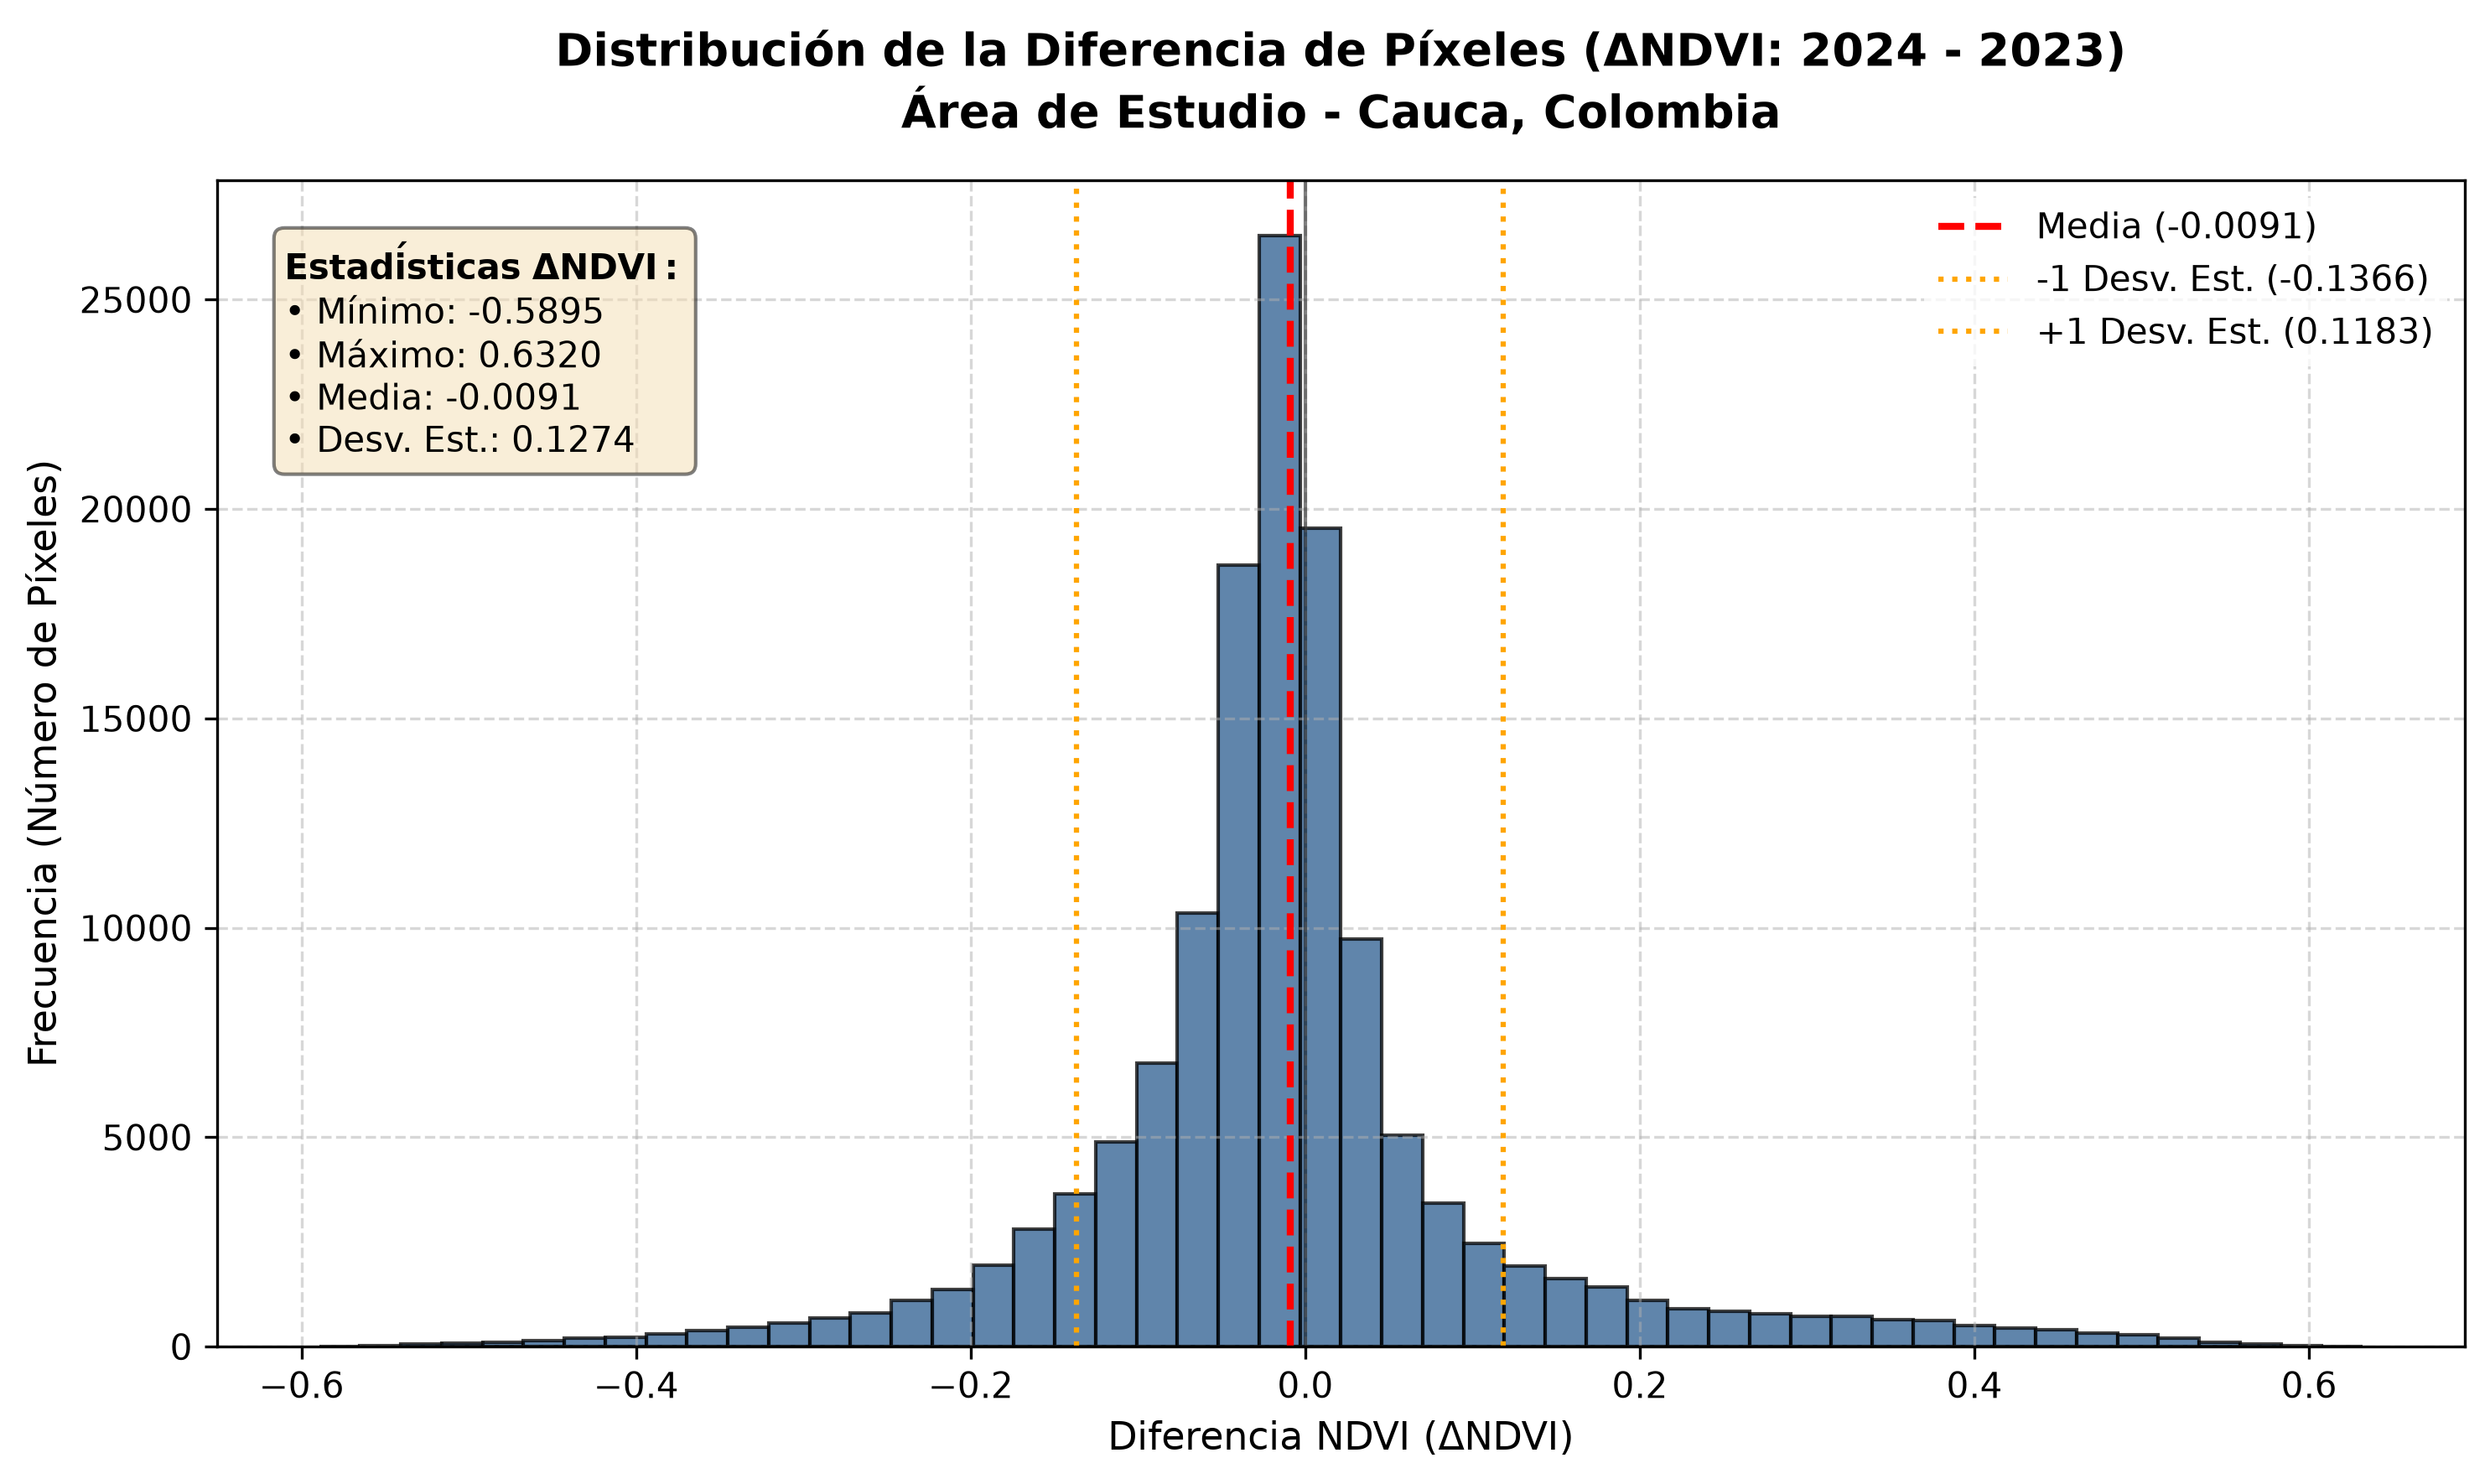

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray as rxr

# ==============================================================================
# 1. CARGAR RASTERS LIMPIOS Y CALCULAR LA DIFERENCIA (ΔNDVI)
# ==============================================================================
ds_2023 = rxr.open_rasterio("ndvi_2023_limpio.tif", masked=True).squeeze()
ds_2024 = rxr.open_rasterio("ndvi_2024_limpio.tif", masked=True).squeeze()

# Asegurar alineación de píxeles
ds_2024_aligned = ds_2024.rio.reproject_match(ds_2023)
diff_raster = ds_2024_aligned - ds_2023

# Extraer arreglos unidimensionales omitiendo valores nulos (NaN)
v_2023 = ds_2023.values[~np.isnan(ds_2023.values)]
v_2024 = ds_2024_aligned.values[~np.isnan(ds_2024_aligned.values)]
v_diff = diff_raster.values[~np.isnan(diff_raster.values)]

# ==============================================================================
# 2. CÁLCULO DE ESTADÍSTICAS DESCRIPTIVAS PONTUALES
# ==============================================================================
stats_data = {
    "Métrica": ["Mínimo (Min)", "Máximo (Max)", "Media (Mean)", "Desviación Estándar (Std Dev)", "Total Píxeles Válidos"],
    "NDVI 2023": [v_2023.min(), v_2023.max(), v_2023.mean(), v_2023.std(), len(v_2023)],
    "NDVI 2024": [v_2024.min(), v_2024.max(), v_2024.mean(), v_2024.std(), len(v_2024)],
    "Diferencia (ΔNDVI)": [v_diff.min(), v_diff.max(), v_diff.mean(), v_diff.std(), len(v_diff)]
}

df_stats = pd.DataFrame(stats_data)
df_stats[["NDVI 2023", "NDVI 2024", "Diferencia (ΔNDVI)"]] = df_stats[["NDVI 2023", "NDVI 2024", "Diferencia (ΔNDVI)"]].round(4)

print("="*70)
print("📊 TABLA DE ESTADÍSTICAS DESCRIPTIVAS (PIXEL DIFFERENCE DISTRIBUTION)")
print("="*70)
print(df_stats.to_string(index=False))
print("="*70)

# ==============================================================================
# 3. GRAFICAR HISTOGRAMA Y DISTRIBUCIÓN
# ==============================================================================
plt.figure(figsize=(10, 6), dpi=300)

# Histograma de la diferencia
counts, bins, patches = plt.hist(v_diff, bins=50, color='#2b5c8f', edgecolor='black', alpha=0.75, density=False)

# Líneas guía estadísticas
mean_val = v_diff.mean()
std_val = v_diff.std()

plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Media ({mean_val:.4f})')
plt.axvline(mean_val - std_val, color='orange', linestyle=':', linewidth=1.5, label=f'-1 Desv. Est. ({mean_val - std_val:.4f})')
plt.axvline(mean_val + std_val, color='orange', linestyle=':', linewidth=1.5, label=f'+1 Desv. Est. ({mean_val + std_val:.4f})')
plt.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)

# Personalización del gráfico
plt.title("Distribución de la Diferencia de Píxeles (ΔNDVI: 2024 - 2023)\nÁrea de Estudio - Cauca, Colombia", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Diferencia NDVI (ΔNDVI)", fontsize=11)
plt.ylabel("Frecuencia (Número de Píxeles)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Texto con la tabla de resumen dentro del gráfico
textstr = '\n'.join((
    r'$\mathbf{Estad\acute{i}sticas\ \Delta NDVI:}$',
    f'• Mínimo: {v_diff.min():.4f}',
    f'• Máximo: {v_diff.max():.4f}',
    f'• Media: {mean_val:.4f}',
    f'• Desv. Est.: {std_val:.4f}'
))
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
plt.gca().text(0.03, 0.95, textstr, transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', bbox=props)

plt.tight_layout()
plt.savefig("ndvi_pixel_difference_histogram.png", dpi=300)
plt.show()